# 01 · Inside the base model's files

What the numbers in a checkpoint are, how they are stored, and what they look like.

No GPU needed. Everything runs on CPU and reads one matrix at a time.
Run from the `notebooks/` folder (or the repo root).

In [ ]:
import sys, json, struct
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, torch, matplotlib.pyplot as plt
from safetensors import safe_open
from src.merge.merge import LazyWeights

BASE = "Qwen/Qwen2.5-1.5B-Instruct"     # HF id (read from your HF cache) or a local folder
SEED = 42
TASKS = ["gsm8k", "logic", "code"]
METHODS = ["avg", "task_arithmetic", "ties"]
MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
SPEC = {t: ROOT / f"checkpoints/specialists/{t}/seed{SEED}" for t in TASKS}
MERGED = {m: ROOT / f"checkpoints/merged/{m}" for m in METHODS}

# fixed colours: tasks always blue/orange/aqua, methods always yellow/magenta/green
C_TASK = dict(zip(TASKS, ["#2a78d6", "#eb6834", "#1baf7a"]))
C_METHOD = dict(zip(METHODS, ["#eda100", "#e87ba4", "#008300"]))
C_MOD = dict(zip(MODULES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]))

torch.set_printoptions(precision=4, sci_mode=False, linewidth=150)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e4e0", "axes.axisbelow": True})

def sub(module):
    return "self_attn" if module in MODULES[:4] else "mlp"

def wname(layer, module):
    return f"model.layers.{layer}.{sub(module)}.{module}.weight"

base = LazyWeights(BASE)
cfg = json.loads((base.path / "config.json").read_text())
N_LAYERS = cfg["num_hidden_layers"]
print("base folder:", base.path)

/mnt/EAD854DBD854A799/IITB Course/Sem 7/CS769 (Optimisation in Machine Learning)/Project (Does RL-induced reasoning survive merging)/Does_RL-induced_reasoning_survive_merging/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 6 files: 100%|██████████| 6/6 [00:00<00:00, 2077.42it/s]

base folder: /home/navya-garg/.cache/huggingface/hub/models--Qwen--Qwen2.5-0.5B-Instruct/snapshots/7ae557604adf67be50417f59c2c2f167def9a775


## 1. What is in the folder

| File | What it holds |
|---|---|
| `config.json` | The architecture recipe: sizes, number of layers, dtype. No weights. |
| `model.safetensors` | Every weight, as named matrices. This is the model. |
| `generation_config.json` | Default decoding settings. |
| `tokenizer*.json`, `vocab.json`, `merges.txt` | Text ↔ token-id mapping. Not weights. |

Bigger models split the weights into `model-0000x-of-0000y.safetensors` plus an index file. `LazyWeights` handles both.

In [2]:
for f in sorted(base.path.iterdir()):
    print(f"{f.name:<32} {f.stat().st_size / 1e6:9.1f} MB")
print()
for k in ["hidden_size", "intermediate_size", "num_hidden_layers", "num_attention_heads",
          "num_key_value_heads", "vocab_size", "tie_word_embeddings", "torch_dtype", "dtype"]:
    if k in cfg:
        print(f"{k:<22} {cfg[k]}")

config.json                            0.0 MB
generation_config.json                 0.0 MB
merges.txt                             1.7 MB
model.safetensors                    988.1 MB
tokenizer.json                         7.0 MB
tokenizer_config.json                  0.0 MB
vocab.json                             2.8 MB

hidden_size            896
intermediate_size      4864
num_hidden_layers      24
num_attention_heads    14
num_key_value_heads    2
vocab_size             151936
tie_word_embeddings    True
torch_dtype            bfloat16


## 2. How a `.safetensors` file is laid out

```
[ 8 bytes: header length N ][ N bytes: JSON header ][ raw numbers, back to back ]
```

The header maps each tensor name to its dtype, shape and byte range.
To read one matrix, a reader jumps straight to its byte range. Nothing else is loaded.
That is why it is "safe" (no code inside, unlike pickle `.bin` files) and fast.

Below: read the header by hand, then decode the first 4 numbers of one matrix from raw bytes.

In [3]:
name = "model.layers.0.self_attn.q_proj.weight"
f = base.key_file[name]
with open(f, "rb") as h:
    n = struct.unpack("<Q", h.read(8))[0]          # little-endian unsigned 64-bit int
    header = json.loads(h.read(n))
    print("header length:", n, "bytes;", len(header), "entries")
    print(name, "->", header[name])

    start = 8 + n + header[name]["data_offsets"][0]
    h.seek(start)
    raw = h.read(8)                                  # 4 numbers x 2 bytes (bf16)

print("\nraw bytes      :", raw.hex(" "))
# bf16 = the top 16 bits of a float32, so pad 2 zero bytes and read as float32
by_hand = [struct.unpack("<f", b"\x00\x00" + raw[i:i + 2])[0] for i in range(0, 8, 2)]
print("decoded by hand:", [round(v, 6) for v in by_hand])
print("via library    :", [round(v, 6) for v in base.get(name).flatten()[:4].float().tolist()])

header length: 32280 bytes; 291 entries
model.layers.0.self_attn.q_proj.weight -> {'dtype': 'BF16', 'shape': [896, 896], 'data_offsets': [300258816, 301864448]}

raw bytes      : fd ba ab bb 9a 3c 4c 3c
decoded by hand: [-0.00193, -0.005219, 0.018799, 0.012451]
via library    : [-0.00193, -0.005219, 0.018799, 0.012451]


## 3. Every tensor, by name

Names follow the module tree: `model.layers.{i}.{block}.{part}.weight`.

| Tensor | Shape | Role |
|---|---|---|
| `embed_tokens.weight` | [vocab, hidden] | One row (vector) per token. |
| `input_layernorm.weight` | [hidden] | Per-feature scale before attention (RMSNorm). |
| `self_attn.q_proj / k_proj / v_proj` | [out, hidden] + bias | Make queries, keys, values. k and v are smaller: 2 KV heads shared by 14 query heads (grouped-query attention). |
| `self_attn.o_proj` | [hidden, hidden] | Mixes the attention heads back together. |
| `post_attention_layernorm.weight` | [hidden] | Scale before the MLP. |
| `mlp.gate_proj / up_proj` | [intermediate, hidden] | Expand to 4864 features (SwiGLU: `silu(gate) * up`). |
| `mlp.down_proj` | [hidden, intermediate] | Shrink back to 896. |
| `model.norm.weight` | [hidden] | Final scale before predicting the next token. |

PyTorch stores a linear layer as `[out, in]`: `y = x @ W.T + b`.
No `lm_head`: with `tie_word_embeddings`, the output layer reuses `embed_tokens`.

**LoRA touches only the 7 matrices `q k v o gate up down` in each layer: 7 × 24 = 168 tensors.**

In [4]:
handles = {f: safe_open(f, "pt") for f in set(base.key_file.values())}
def shape(k):
    return tuple(handles[base.key_file[k]].get_slice(k).get_shape())

for k in base.keys():
    if ".layers." not in k or ".layers.0." in k:
        print(f"{k:<50} {str(shape(k)):<14} {np.prod(shape(k)) / 1e6:7.3f}M")
print(f"... the same {sum('.layers.0.' in k for k in base.keys())} tensors repeat for layers 1-{N_LAYERS - 1}")

model.embed_tokens.weight                          (151936, 896)  136.135M
model.layers.0.input_layernorm.weight              (896,)           0.001M
model.layers.0.mlp.down_proj.weight                (896, 4864)      4.358M
model.layers.0.mlp.gate_proj.weight                (4864, 896)      4.358M
model.layers.0.mlp.up_proj.weight                  (4864, 896)      4.358M
model.layers.0.post_attention_layernorm.weight     (896,)           0.001M
model.layers.0.self_attn.k_proj.bias               (128,)           0.000M
model.layers.0.self_attn.k_proj.weight             (128, 896)       0.115M
model.layers.0.self_attn.o_proj.weight             (896, 896)       0.803M
model.layers.0.self_attn.q_proj.bias               (896,)           0.001M
model.layers.0.self_attn.q_proj.weight             (896, 896)       0.803M
model.layers.0.self_attn.v_proj.bias               (128,)           0.000M
model.layers.0.self_attn.v_proj.weight             (128, 896)       0.115M
model.norm.weight        

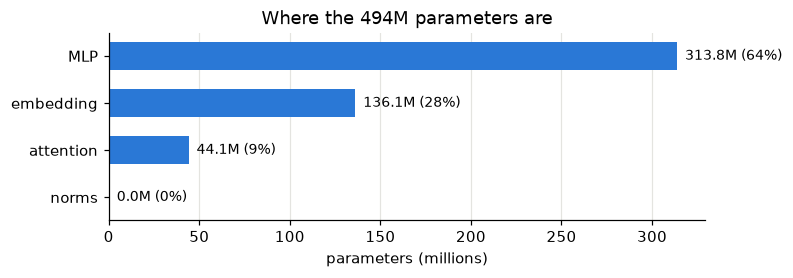

In [5]:
def group(k):
    if "embed" in k: return "embedding"
    if "self_attn" in k: return "attention"
    if "mlp" in k: return "MLP"
    return "norms"

counts = {}
for k in base.keys():
    counts[group(k)] = counts.get(group(k), 0) + int(np.prod(shape(k)))
counts = dict(sorted(counts.items(), key=lambda kv: kv[1]))
total = sum(counts.values())

fig, ax = plt.subplots(figsize=(7, 2.2))
ax.barh(list(counts), [v / 1e6 for v in counts.values()], color="#2a78d6", height=0.6)
for i, v in enumerate(counts.values()):
    ax.text(v / 1e6, i, f"  {v / 1e6:.1f}M ({v / total:.0%})", va="center", fontsize=9)
ax.set_xlabel("parameters (millions)"); ax.grid(axis="y", visible=False)
ax.set_title(f"Where the {total / 1e6:.0f}M parameters are")
plt.show()

## 4. The real numbers

A corner of the layer-0 query matrix. Each entry is one connection weight.
Values are small (around ±0.05): typical for trained transformers.

In [6]:
L = 0
W = base.get(wname(L, "q_proj"))
print("dtype:", W.dtype, " shape:", tuple(W.shape))
print(W[:6, :8].float())
Wf = W.float()
print(f"\nmean {Wf.mean():+.5f}  std {Wf.std():.5f}  min {Wf.min():+.3f}  max {Wf.max():+.3f}")
print("bias (first 8):", base.get(wname(L, "q_proj").replace("weight", "bias"))[:8].float())
print("layernorm scale (first 8):", base.get(f"model.layers.{L}.input_layernorm.weight")[:8].float())

dtype: torch.bfloat16  shape: (896, 896)
tensor([[-0.0019, -0.0052,  0.0188,  0.0125,  0.0040, -0.0092,  0.0058, -0.0017],
        [ 0.0084,  0.0018,  0.0435,  0.0183,  0.0003,  0.0425, -0.0153, -0.0147],
        [-0.0168, -0.0248,  0.0422,  0.0344, -0.0064,  0.0262,  0.0085, -0.0280],
        [-0.0101,  0.0113, -0.0310,  0.0042,  0.0439, -0.0238,  0.0142,  0.0038],
        [ 0.0479, -0.0703, -0.0010,  0.0771,  0.0562,  0.0219,  0.0306,  0.0601],
        [ 0.0146, -0.0038, -0.0232, -0.0123,  0.0001,  0.0052, -0.0236, -0.0165]])

mean -0.00002  std 0.06674  min -1.227  max +1.172
bias (first 8): tensor([ -0.0150,   0.0255,  -0.1035,  -0.1357, -14.4375,   0.2656,   0.3242,   0.1240])
layernorm scale (first 8): tensor([-0.0469,  0.0444, -0.0254,  0.0845, -0.0437,  0.0391, -0.0417, -0.0267])


### Why bf16 matters

bf16 keeps only 8 bits of precision: about 2–3 significant digits.
Near 0.02, the gap between neighbouring bf16 values is about 0.00012 (≈0.4–0.8% of the value).
So a weight change smaller than ~0.4% of the weight is rounded away when saved in bf16.
LoRA updates are often that small. Notebook 02 checks how much of the update survives.

In [7]:
x = torch.tensor([0.02000, 0.02003, 0.02006, 0.02010, 0.02020, 0.02050])
print("float32 :", [f"{v:.5f}" for v in x.tolist()])
print("bf16    :", [f"{v:.5f}" for v in x.bfloat16().float().tolist()])

float32 : ['0.02000', '0.02003', '0.02006', '0.02010', '0.02020', '0.02050']
bf16    : ['0.02002', '0.02002', '0.02002', '0.02014', '0.02014', '0.02051']


## 5. How the values are spread

Histograms of one matrix of each kind, first vs last layer. Log y-axis, so the rare large values show.
Bell shape around 0 with a few outliers is normal.

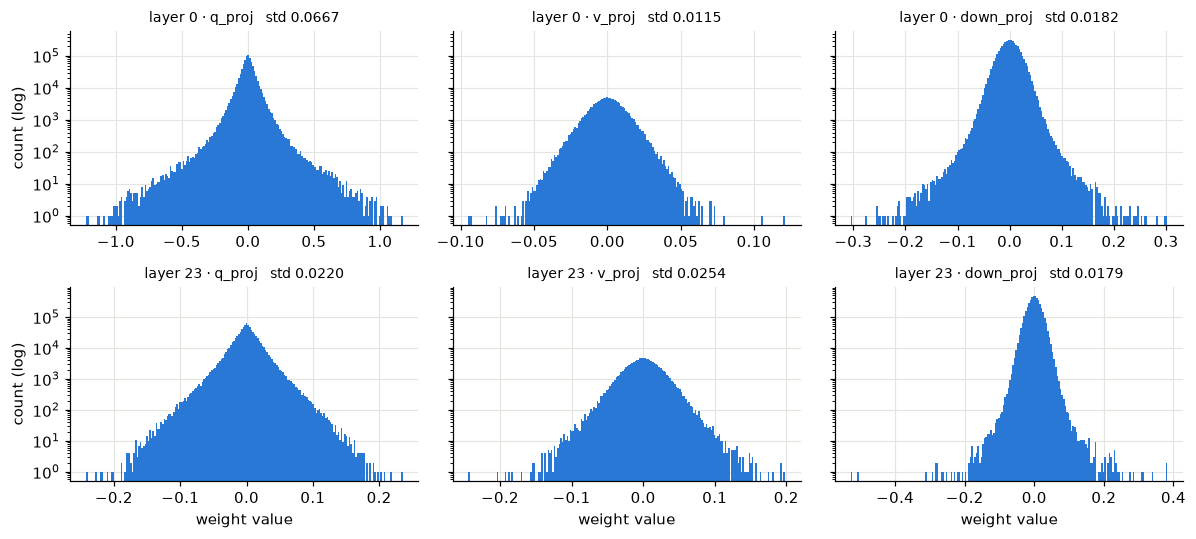

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharey="row")
for row, layer in enumerate([0, N_LAYERS - 1]):
    for ax, m in zip(axes[row], ["q_proj", "v_proj", "down_proj"]):
        v = base.get(wname(layer, m)).float().flatten().numpy()
        ax.hist(v, bins=200, color="#2a78d6", log=True)
        ax.set_title(f"layer {layer} · {m}   std {v.std():.4f}", fontsize=9)
for ax in axes[1]: ax.set_xlabel("weight value")
for ax in axes[:, 0]: ax.set_ylabel("count (log)")
plt.tight_layout(); plt.show()

## 6. A matrix as a picture

Left: a 64×64 corner, each pixel one weight (red +, blue −, white 0).
Right: the whole matrix, |W| averaged over blocks. Bright rows/columns are "outlier" features
that carry unusually large weights in many LLMs.

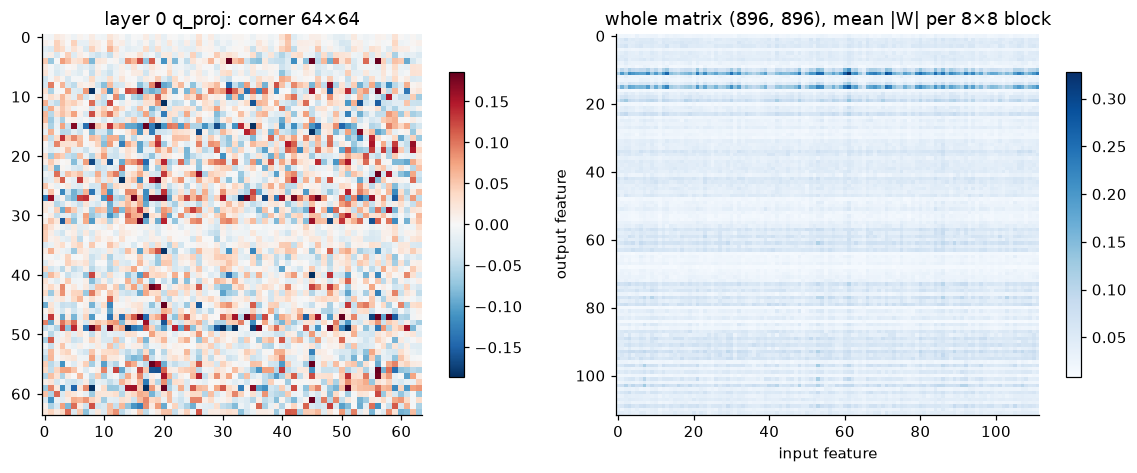

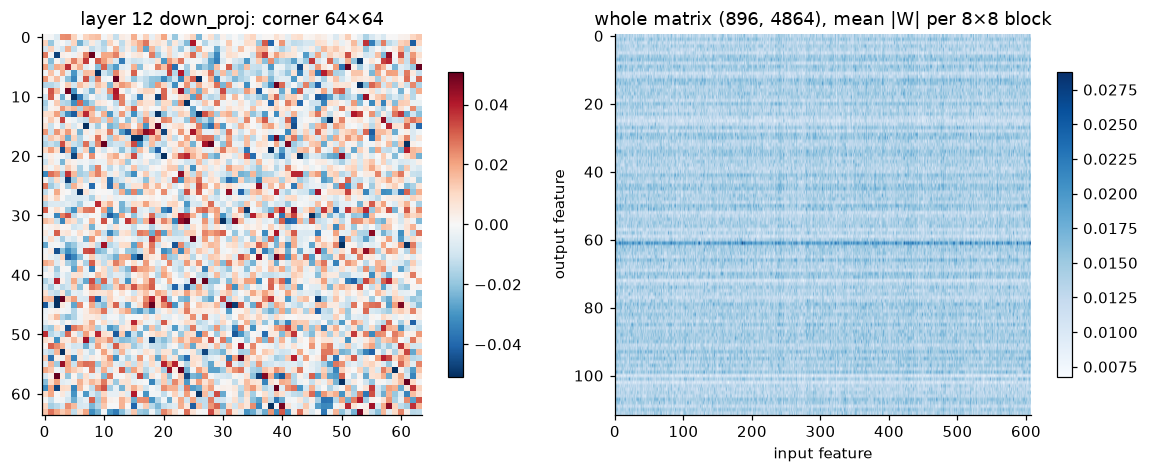

In [9]:
def show_matrix(W, title):
    W = W.float()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    patch = W[:64, :64]
    v = patch.abs().quantile(0.99).item()
    im = axes[0].imshow(patch, cmap="RdBu_r", vmin=-v, vmax=v)
    axes[0].set_title(f"{title}: corner 64×64"); plt.colorbar(im, ax=axes[0], shrink=0.8)
    k = max(1, min(W.shape) // 112)
    pooled = torch.nn.functional.avg_pool2d(W.abs()[None, None], k)[0, 0]
    im = axes[1].imshow(pooled, cmap="Blues", aspect="auto")
    axes[1].set_title(f"whole matrix {tuple(W.shape)}, mean |W| per {k}×{k} block")
    axes[1].set_xlabel("input feature"); axes[1].set_ylabel("output feature")
    plt.colorbar(im, ax=axes[1], shrink=0.8)
    for ax in axes: ax.grid(False)
    plt.tight_layout(); plt.show()

show_matrix(base.get(wname(0, "q_proj")), "layer 0 q_proj")
show_matrix(base.get(wname(N_LAYERS // 2, "down_proj")), f"layer {N_LAYERS // 2} down_proj")

## 7. Across layers

Root-mean-square size of each matrix type, layer by layer.
RMS (not the plain norm) so big and small matrices are comparable.

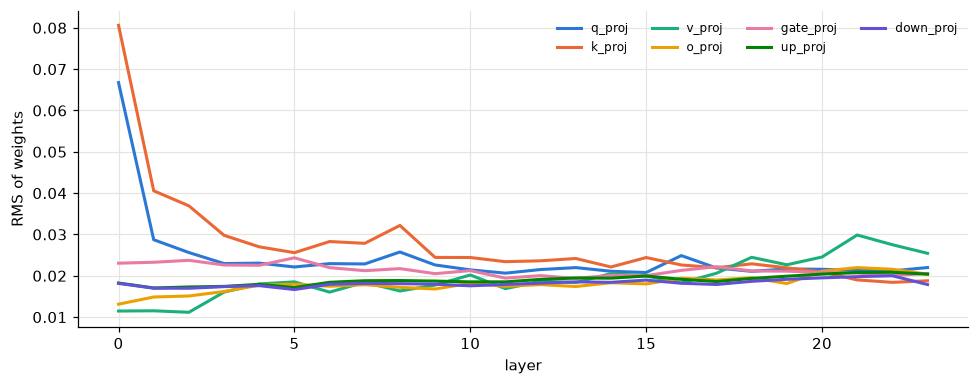

In [10]:
rms = {m: [base.get(wname(l, m)).float().pow(2).mean().sqrt().item() for l in range(N_LAYERS)] for m in MODULES}
fig, ax = plt.subplots(figsize=(9, 3.6))
for m in MODULES:
    ax.plot(range(N_LAYERS), rms[m], color=C_MOD[m], lw=2, label=m)
ax.set_xlabel("layer"); ax.set_ylabel("RMS of weights")
ax.legend(ncol=4, fontsize=8, frameon=False)
plt.tight_layout(); plt.show()